# 6. The Sparse Target Network

> **Overview.** Does the method find the deep sparse target network, where unit search from prior work did no better
> than random sparse wiring?

**Setup.** The target network of `../sparse_teacher.ipynb`: 1000 inputs, 3 hidden layers of 20 target LTUs, each
reading 10 lower units, and 100 outputs. The learner: notebook 5's method with 40 LTUs per depth. Against generate and
test with randomly wired LTUs (prior work), LTUs wired like the target network (reference), fully connected networks
with network Autostep and with Adam, and the linear learner (baselines). Then the method with 20 and 80 LTUs per depth.
5 seeds; 1M steps.

In [1]:
import os
from time import perf_counter
from typing import NamedTuple

os.environ['XLA_PYTHON_CLIENT_PREALLOCATE'] = 'false'   # take GPU memory only as needed, so the GPU can be shared
import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import optax

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem (as in sparse_teacher.ipynb) ---
N_INPUTS, N_OUTPUTS = 1000, 100
N_DEPTHS = 3                         # hidden layers, of the target network and of the learner
TEACHER_WIDTH = 20                   # target LTUs per hidden layer
TEACHER_FAN_IN = 10                  # each target LTU and output reads this many units of lower depths
FIRING_RATE = 0.3                    # each target LTU's threshold makes it fire this often
NOISE_STD = 0.1                      # observation noise on each output: the RMSE floor

# --- Learner ---
STAT_RATE, VAR_FLOOR = 1e-3, 0.01    # standardization of the hidden units
INIT_STEP_SIZE = 1e-4                # Autostep's initial step-size
META_STEP_SIZE, TAU = 0.02, 1e4
WIDTH = 40                           # hidden LTUs per depth
FAN_IN = 20                          # a new LTU first reads this many sources
REPLACED_SHARE = 1 / 8               # share of the LTUs replaced at each search step, the weakest
FAST_STEP_SIZE = 3e-2                # initial step-size of a new LTU's input weights
GROW_Z = 6.0                         # an LTU connects a source whose gradient sum is this many RMS above the rest
FLAT_SHARE = 0.1                     # an LTU with less than this share of its input |weights| on the layer below
                                     # acts as an LTU of that layer

# --- Fully connected baseline (as in sparse_teacher.ipynb) ---
DENSE_WIDTH = 160                    # LTUs per hidden layer
DENSE_META_STEP_SIZE = 0.01

# --- Adam baseline: fully connected, DENSE_WIDTH LTUs per hidden layer ---
ADAM_POWER = -14                     # Adam's step-size 2^ADAM_POWER, the best of 2^-18 to 2^-8 (one seed each)

# --- Experiment ---
LINEAR_STEPS = 0                     # no linear-learner phase: the LTUs are added at step 0
NUM_STEPS = 1_000_000                # steps after the LTUs are added
WINDOW = 1_000                       # steps per recorded RMSE
N_SEEDS = 5
PERIOD = 10_000                      # steps between search steps

## Target

In [3]:
def make_teacher(key, n_samples=20_000):
    # A sparse LTU network. Each hidden unit, at depth d, reads TEACHER_FAN_IN distinct units of lower depths, each
    # picked by choosing a lower depth uniformly (depth 0 being the inputs) and then a unit of that depth; each output
    # does the same over hidden depths only. Weights are N(0, 1), each hidden unit's threshold makes it fire
    # FIRING_RATE of the time, and each output is scaled to zero mean and unit variance. Units are stored by depth:
    # sources are [inputs, hidden units], hidden unit u of depth d being slot (d - 1) * TEACHER_WIDTH + u.
    n_hidden = N_DEPTHS * TEACHER_WIDTH
    depth = jnp.repeat(jnp.arange(1, N_DEPTHS + 1), TEACHER_WIDTH)
    source_depth = jnp.concatenate([jnp.zeros(N_INPUTS, int), depth])
    group_size = jnp.array([N_INPUTS] + [TEACHER_WIDTH] * N_DEPTHS)

    def pick(key, allowed):
        # TEACHER_FAN_IN distinct sources: a uniformly chosen allowed depth, then a uniformly chosen unit in it
        # (Gumbel top-k, which samples without replacement in proportion to these probabilities).
        p = jnp.where(allowed[source_depth], 1.0 / group_size[source_depth], 0.0)
        gumbel = jax.random.gumbel(key, p.shape)
        top = jax.lax.top_k(jnp.where(p > 0, jnp.log(p) + gumbel, -jnp.inf), TEACHER_FAN_IN)[1]
        return jnp.zeros(p.shape, bool).at[top].set(True)

    keys = jax.random.split(key, 4)
    lower = jnp.arange(N_DEPTHS + 1)[None, :] < depth[:, None]                    # (unit, depth) allowed sources
    hidden_mask = jax.vmap(pick)(jax.random.split(keys[0], n_hidden), lower)
    output_allowed = (jnp.arange(N_DEPTHS + 1) > 0)
    output_mask = jax.vmap(lambda k: pick(k, output_allowed))(jax.random.split(keys[1], N_OUTPUTS))[:, N_INPUTS:]
    hidden_w = jax.random.normal(keys[2], hidden_mask.shape) * hidden_mask
    output_w = jax.random.normal(keys[3], output_mask.shape) * output_mask

    # Thresholds, depth by depth, from a batch of inputs.
    x = jax.random.normal(jax.random.fold_in(key, 1), (n_samples, N_INPUTS))
    bits = jnp.zeros((n_samples, n_hidden))
    threshold = jnp.zeros(n_hidden)
    for d in range(1, N_DEPTHS + 1):
        z = jnp.concatenate([x, bits], axis=1) @ hidden_w.T
        threshold = jnp.where(depth == d, jnp.quantile(z, 1 - FIRING_RATE, axis=0), threshold)
        bits = jnp.where(depth == d, (z > threshold).astype(jnp.float32), bits)
    raw = bits @ output_w.T
    return {'hidden_w': hidden_w, 'threshold': threshold, 'depth': depth, 'output_w': output_w,
            'output_mean': raw.mean(0), 'output_std': raw.std(0)}


def teacher_targets(teacher, x):
    bits = jnp.zeros(N_DEPTHS * TEACHER_WIDTH)
    for d in range(1, N_DEPTHS + 1):
        z = teacher['hidden_w'] @ jnp.concatenate([x, bits])
        bits = jnp.where(teacher['depth'] == d, (z > teacher['threshold']).astype(jnp.float32), bits)
    return (teacher['output_w'] @ bits - teacher['output_mean']) / teacher['output_std']


TEACHER = make_teacher(jax.random.PRNGKey(123))
# The target network's weights over [inputs, target LTUs], for wiring LTUs like it: its LTUs' and its outputs' (0 on
# the inputs).
TARGET_W = TEACHER['hidden_w']
TARGET_OUT = jnp.concatenate([jnp.zeros((N_OUTPUTS, N_INPUTS)), TEACHER['output_w']], 1)


def next_sample(key):
    # One sample: standard normal inputs, and the target network's outputs plus N(0, NOISE_STD^2) noise.
    x_key, noise_key = jax.random.split(key)
    x = jax.random.normal(x_key, (N_INPUTS,))
    return x, teacher_targets(TEACHER, x) + NOISE_STD * jax.random.normal(noise_key, (N_OUTPUTS,))

## Learner

Notebook 5's learner, with three hidden layers. The fully connected baselines' code is at the end.

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


@jax.custom_vjp
def standardize(bits, mean, error_mean, error_h_mean):
    return (bits - mean) / jnp.sqrt(jnp.maximum(mean * (1 - mean), VAR_FLOOR))


def standardize_fwd(bits, mean, error_mean, error_h_mean):
    variance = mean * (1 - mean)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - mean) / scale
    return h, (h, scale, variance > VAR_FLOOR, error_mean, error_h_mean)


def standardize_bwd(saved, g):
    h, scale, unfloored, error_mean, error_h_mean = saved
    return (g - error_mean - jnp.where(unfloored, h * error_h_mean, 0.)) / scale, None, None, None


standardize.defvjp(standardize_fwd, standardize_bwd)


class Stats(NamedTuple):
    # Running statistics of the hidden units, each shaped like the hidden units.
    hidden_mean: jax.Array      # firing rate
    error_mean: jax.Array       # means of the error g arriving at each hidden unit, and of g * h
    error_h_mean: jax.Array


def set_width(width):
    # Sizes the learner: `width` hidden units per depth (PER_DEPTH), N_LTUS in all, of which search replaces REPLACED;
    # each hidden unit's depth (SLOT_DEPTH); the hidden units of each depth (DEPTHS); and LOWER[u, j], whether hidden
    # unit u may read source j of [inputs, hidden units, 1]: every input and the bias, and the hidden units of lower
    # depth.
    global PER_DEPTH, N_LTUS, REPLACED, SLOT_DEPTH, DEPTHS, LOWER
    PER_DEPTH, N_LTUS = width, N_DEPTHS * width
    REPLACED = round(REPLACED_SHARE * N_LTUS)
    SLOT_DEPTH = jnp.arange(N_LTUS) // PER_DEPTH + 1
    DEPTHS = [slice(d * PER_DEPTH, (d + 1) * PER_DEPTH) for d in range(N_DEPTHS)]
    LOWER = (jnp.ones((N_LTUS, N_INPUTS + N_LTUS + 1), bool)
             .at[:, N_INPUTS:-1].set(SLOT_DEPTH[None] < SLOT_DEPTH[:, None]))


set_width(WIDTH)


class Net(NamedTuple):
    # w['hidden'] is the hidden units' weights over [inputs, hidden units, 1 (the bias)], of which they read those in
    # `reads`; w['output'] is the outputs' weights over [inputs (the linear learner), the hidden units, 1]. `mask` says
    # which of the outputs' connections exist; the hidden units' are switched on when the units are added.
    w: dict                     # {'hidden': (N_LTUS, N_INPUTS + N_LTUS + 1), 'output': (N_OUTPUTS, N_INPUTS + N_LTUS + 1)}
    reads: jax.Array            # shaped like w['hidden']
    mask: jax.Array             # shaped like w['output']
    opt: IDBDState
    stats: Stats
    shadow: jax.Array           # (N_OUTPUTS, N_LTUS): each hidden unit's shadow weight on an output, and
    shadow_hidden: jax.Array    # (N_LTUS, N_LTUS) on a higher hidden unit (rows): +-1 on one output or unit, 0 elsewhere
    candidates: jax.Array       # (N_LTUS, N_INPUTS + N_LTUS): sum of dL/dz * source since each unit's last new connection


def active(net):
    # Which slots hold a hidden unit.
    return jnp.any(net.shadow != 0, 0) | jnp.any(net.shadow_hidden != 0, 0)


def parent_weights(net):
    # Shaped like w['hidden']: each hidden unit's shadow weight times its parent's weights on the sources it may
    # read (an output's weight on an input is the linear learner's), 0 elsewhere and on the bias.
    targets = net.shadow.T @ net.w['output'] + net.shadow_hidden.T @ (net.w['hidden'] * net.reads)
    return targets.at[:, -1].set(0.0) * LOWER


def usefulness(net):
    # Each hidden unit's sum of |outgoing weights|, to the outputs and to higher hidden units.
    return (jnp.abs(net.w['output'][:, N_INPUTS:-1]).sum(0)
            + jnp.abs(net.w['hidden'][:, N_INPUTS:-1] * net.reads[:, N_INPUTS:-1]).sum(0))


def init_net(key, units, sampled):
    # `units` hidden units (the rest of the N_LTUS slots left empty), each pair of a depth wired like one target LTU of
    # that depth in turn, reading its inputs, the units of lower depths wired like the target LTUs it reads, and the
    # bias, with LeCun uniform weights over their fan-in; their shadow weights +1 and -1 alternately, each on an output
    # drawn at random among those that read its target LTU (among all outputs if sampled, or if none does); every other
    # weight at 0.
    w_key, out_key = jax.random.split(key)
    slot = jnp.arange(N_LTUS)
    assigned = (SLOT_DEPTH - 1) * TEACHER_WIDTH + slot % PER_DEPTH // 2 % TEACHER_WIDTH  # the target LTU each is wired like
    target_reads = TARGET_W[assigned] != 0
    wired = jnp.concatenate([target_reads[:, :N_INPUTS], target_reads[:, N_INPUTS:][:, assigned],
                             jnp.ones((N_LTUS, 1), bool)], 1)
    reads = wired & LOWER
    fan_in = reads[:, :-1].sum(1, keepdims=True)
    readers = (TARGET_OUT[:, N_INPUTS + assigned] != 0) | sampled
    readers = readers | ~readers.any(0)
    shadow_out = jnp.argmax(jnp.where(readers, jax.random.gumbel(out_key, readers.shape), -jnp.inf), 0)
    sign = jnp.where(slot < units, jnp.where(slot % 2 == 0, 1.0, -1.0), 0.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == shadow_out) * sign
    mask = jnp.ones((N_OUTPUTS, N_INPUTS + N_LTUS + 1), bool).at[:, N_INPUTS:-1].set(False)
    w = {'hidden': (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0)
                    * jnp.sqrt(3.0 / fan_in) * reads).at[:, -1].set(0.0),
         'output': jnp.zeros((N_OUTPUTS, N_INPUTS + N_LTUS + 1))}
    stats = Stats(jnp.full(N_LTUS, 0.5), jnp.zeros(N_LTUS), jnp.zeros(N_LTUS))
    return Net(w, reads, mask, OPTIMIZER.init(w), stats, shadow, jnp.zeros((N_LTUS, N_LTUS)),
               jnp.zeros((N_LTUS, N_INPUTS + N_LTUS)))


def redraw(net, key, replaced):
    # The `replaced` hidden units' new shadow weights, +1 or -1 by slot, each on a unit of a higher layer, their parent:
    # a layer drawn uniformly among those above the unit's depth, the outputs (layer N_DEPTHS + 1) included, then a
    # unit of it at random.
    layer_key, unit_key = jax.random.split(key)
    slot = jnp.arange(N_LTUS)
    layer = jax.random.randint(layer_key, (N_LTUS,), SLOT_DEPTH + 1, N_DEPTHS + 2)
    on_output = layer > N_DEPTHS
    index = jax.random.randint(unit_key, (N_LTUS,), 0, jnp.where(on_output, N_OUTPUTS, PER_DEPTH))
    sign = jnp.where(slot % 2 == 0, 1.0, -1.0)
    shadow = (jnp.arange(N_OUTPUTS)[:, None] == index) * jnp.where(on_output, sign, 0.0)
    shadow_hidden = (slot[:, None] == (layer - 1) * PER_DEPTH + index) * jnp.where(on_output, 0.0, sign)
    return net._replace(shadow=jnp.where(replaced, shadow, net.shadow),
                        shadow_hidden=jnp.where(replaced, shadow_hidden, net.shadow_hidden))


def rewire(net, key, replaced, rows, random):
    # The `rows` hidden units (a mask over slots, among the `replaced` units) each read FAN_IN sources (no more than
    # their parent has nonzero weights on) and the bias, the sources, inputs and lower-depth units alike, drawn without
    # replacement with probability proportional to the square of their parent's weight on them (uniformly among the
    # sources they may read, if random) (Gumbel top-k), with fresh LeCun uniform weights over their fan-in, output
    # weights at 0, and fresh statistics, Autostep state and gradient sums; the other units' connections from the
    # replaced units are cut. Then every unit reads the units with shadow weights on it, connections it lacks starting
    # at weight 0 with step-size FAST_STEP_SIZE.
    draw_key, w_key = jax.random.split(key)
    cut = jnp.zeros_like(net.reads).at[:, N_INPUTS:-1].set(replaced[None])   # connections from the replaced units
    weights = jnp.where(cut, 0.0, jnp.where(random, LOWER, parent_weights(net)))[:, :-1]
    fan_in = jnp.minimum(FAN_IN, (weights != 0).sum(1, keepdims=True))
    scores = jnp.log(weights ** 2) + jax.random.gumbel(draw_key, weights.shape)
    reads = jnp.append(jnp.argsort(jnp.argsort(-scores)) < fan_in, jnp.ones((N_LTUS, 1), bool), axis=1)
    hidden = (jax.random.uniform(w_key, reads.shape, minval=-1.0, maxval=1.0) * jnp.sqrt(3.0 / jnp.maximum(fan_in, 1))
              * reads)
    changed = rows[:, None] | cut
    reads = jnp.where(changed, reads, net.reads)
    served = jnp.zeros_like(reads).at[:, N_INPUTS:-1].set(net.shadow_hidden != 0) & ~reads
    where = {'hidden': changed,
             'output': jnp.concatenate([jnp.zeros(N_INPUTS, bool), rows, jnp.zeros(1, bool)])[None]}
    reset = lambda tree, fresh: jax.tree.map(lambda m, a, b: jnp.where(m, a, b), where, fresh, tree)
    w = reset(net.w, {'hidden': hidden.at[:, -1].set(0.0), 'output': jnp.zeros_like(net.w['output'])})
    zeros = jax.tree.map(jnp.zeros_like, net.w)
    beta = reset(net.opt.beta, jax.tree.map(lambda a: a + net.opt.init_beta, zeros))
    beta = {**beta, 'hidden': jnp.where(served, jnp.log(FAST_STEP_SIZE), beta['hidden'])}
    opt = net.opt._replace(beta=beta, h=reset(net.opt.h, zeros), v=reset(net.opt.v, zeros))
    stats = Stats(*(jnp.where(rows, fresh, old) for fresh, old in zip((0.5, 0.0, 0.0), net.stats)))
    return net._replace(w=w, reads=reads | served, opt=opt, stats=stats,
                        candidates=jnp.where(changed[:, :-1], 0.0, net.candidates))


def speed_up(net, replaced):
    # The `replaced` hidden units' weights keep their magnitudes but take the signs of their shadow weight times their
    # parent's weights on those sources (keeping theirs where that weight is 0), and the step-sizes of all their
    # weights but the bias's start at FAST_STEP_SIZE.
    sources = net.reads.at[:, -1].set(False) & replaced[:, None]
    parent = parent_weights(net)
    hidden = jnp.where(sources & (parent != 0), jnp.abs(net.w['hidden']) * jnp.sign(parent), net.w['hidden'])
    beta = jnp.where(sources, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': hidden}, opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}))


def grow(net):
    # Each hidden unit whose largest gradient sum, over the sources it may read but does not, is more than GROW_Z times
    # their root mean square connects that source, at weight 0 with step-size FAST_STEP_SIZE, and restarts its sums.
    unread = LOWER[:, :-1] & ~net.reads[:, :-1]
    sums = jnp.where(unread, jnp.abs(net.candidates), 0.0)
    rms = jnp.sqrt(jnp.sum(sums ** 2, 1) / unread.sum(1))
    best = jnp.argmax(sums, 1)
    grows = (jnp.max(sums, 1) > GROW_Z * rms) & active(net)
    new = (jnp.arange(N_INPUTS + N_LTUS + 1) == best[:, None]) & grows[:, None]
    beta = jnp.where(new, jnp.log(FAST_STEP_SIZE), net.opt.beta['hidden'])
    return net._replace(w={**net.w, 'hidden': jnp.where(new, 0.0, net.w['hidden'])}, reads=net.reads | new,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}),
                        candidates=jnp.where(grows[:, None], 0.0, net.candidates))


def learn(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs, the hidden units computed
    # depth by depth, each shadow weight standing in for its hidden unit's weight to that output or higher unit in the
    # backward pass while the real one is smaller in magnitude, the other weights used as they are. Returns the new
    # network and the squared error on this sample averaged over the outputs, before learning from it, and adds
    # dL/dz * source to each hidden unit's gradient sums. `probe` is zero; its gradients are the error arriving at each
    # hidden unit and dL/dz.

    def loss_fn(w, probe):
        w = {'hidden': w['hidden'] * net.reads, 'output': w['output'] * net.mask}

        def back(shadow, real):
            # The weights used in the backward pass: each shadow weight while the real one is smaller in magnitude.
            return jax.lax.stop_gradient(jnp.where((shadow != 0) & (jnp.abs(real) < 1.0), shadow, real))

        hidden_back = back(net.shadow_hidden, w['hidden'][:, N_INPUTS:-1])
        a, means, hs = jnp.zeros(N_LTUS), [], []
        for rows in DEPTHS:
            through_back = hidden_back[rows] @ a
            z = (w['hidden'][rows] @ jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)])) + through_back
                 - jax.lax.stop_gradient(through_back))
            b = ltu(z + probe[1][rows])
            mean = net.stats.hidden_mean[rows] + STAT_RATE * (jax.lax.stop_gradient(b) - net.stats.hidden_mean[rows])
            h = standardize(b, mean, net.stats.error_mean[rows], net.stats.error_h_mean[rows])
            a = a.at[rows].set(h + probe[0][rows])
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jax.lax.stop_gradient(jnp.concatenate([x, a, jnp.ones(1)]))
        through_back = (back(net.shadow, w['output'][:, N_INPUTS:-1]) * net.mask[:, N_INPUTS:-1]) @ a
        prediction = w['output'] @ source + through_back - jax.lax.stop_gradient(through_back)
        return 0.5 * jnp.sum((prediction - y) ** 2), (source, jnp.concatenate(hs), jnp.concatenate(means))

    (loss, (source, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(net.w, (jnp.zeros(N_LTUS),) * 2)
    grads = {'hidden': grads['hidden'] * net.reads, 'output': grads['output'] * net.mask}
    error, dz = error
    sources = {'hidden': source[None] * net.reads, 'output': source[None] * net.mask}
    updates, opt = OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return net._replace(w=jax.tree.map(jnp.add, net.w, updates), opt=opt, stats=stats,
                        candidates=net.candidates + dz[:, None] * source[:-1]), 2 * loss / N_OUTPUTS


# --- The fully connected baseline, as in sparse_teacher.ipynb: hidden layers of DENSE_WIDTH units, each reading the
# layer below, and the outputs reading the last; one weight matrix per layer, the last column the bias ---
DENSE_OPTIMIZER = optax_idbd(meta_lr=DENSE_META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                             version='squared_inputs')
LAYERS = [f'layer {d}' for d in range(1, N_DEPTHS + 1)] + ['output']


class Dense(NamedTuple):
    w: dict                     # LAYERS -> (units, units below + 1)
    opt: IDBDState
    stats: Stats                # each (N_DEPTHS, DENSE_WIDTH)


def init_dense(key):
    # Hidden weights U(-INIT_STEP_SIZE, INIT_STEP_SIZE), output weights 0, biases 0.
    shapes = [(DENSE_WIDTH, N_INPUTS + 1)] + [(DENSE_WIDTH, DENSE_WIDTH + 1)] * (N_DEPTHS - 1)
    w = {k: jax.random.uniform(key, shape, minval=-INIT_STEP_SIZE, maxval=INIT_STEP_SIZE).at[:, -1].set(0.0)
         for k, key, shape in zip(LAYERS, jax.random.split(key, len(LAYERS)), shapes)}
    w['output'] = jnp.zeros((N_OUTPUTS, DENSE_WIDTH + 1))
    shape = (N_DEPTHS, DENSE_WIDTH)
    return Dense(w, DENSE_OPTIMIZER.init(w), Stats(jnp.full(shape, 0.5), jnp.zeros(shape), jnp.zeros(shape)))


def learn_dense(net, x, y):
    # One online network-Autostep update on half the squared error summed over the outputs. Returns the new network
    # and the squared error on this sample averaged over the outputs, before learning from it. `probe` is zero; its
    # gradient is the error arriving at each hidden unit.
    def loss_fn(w, probe):
        a, sources, means, hs = x, {}, [], []
        for d, k in enumerate(LAYERS[:-1]):
            source = jnp.append(a, 1.0)
            sources[k] = jnp.broadcast_to(jax.lax.stop_gradient(source), w[k].shape)
            stats = jax.tree.map(lambda s: s[d], net.stats)
            b = ltu(w[k] @ source)
            mean = stats.hidden_mean + STAT_RATE * (jax.lax.stop_gradient(b) - stats.hidden_mean)
            h = standardize(b, mean, stats.error_mean, stats.error_h_mean)
            a = h + probe[d]
            means.append(mean)
            hs.append(jax.lax.stop_gradient(h))
        source = jnp.append(a, 1.0)
        sources['output'] = jnp.broadcast_to(jax.lax.stop_gradient(source), w['output'].shape)
        return 0.5 * jnp.sum((w['output'] @ source - y) ** 2), (sources, jnp.stack(hs), jnp.stack(means))

    (loss, (sources, h, mean)), (grads, error) = jax.value_and_grad(loss_fn, (0, 1), has_aux=True)(
        net.w, jnp.zeros(net.stats.hidden_mean.shape))
    updates, opt = DENSE_OPTIMIZER.update((grads, None, sources), net.opt, net.w)
    stats = Stats(mean, net.stats.error_mean + STAT_RATE * (error - net.stats.error_mean),
                  net.stats.error_h_mean + STAT_RATE * (error * h - net.stats.error_h_mean))
    return Dense(jax.tree.map(jnp.add, net.w, updates), opt, stats), 2 * loss / N_OUTPUTS


# --- The Adam baseline: hidden layers of DENSE_WIDTH LTUs, each reading the inputs and every lower layer, and the
# outputs reading the inputs and every hidden layer; one weight matrix per layer, the last column the bias ---
ADAM = optax.scale_by_adam()


def init_adam(key):
    # LeCun uniform weights, biases 0.
    w = []
    for d, k in enumerate(jax.random.split(key, N_DEPTHS + 1)):
        fan_in = N_INPUTS + d * DENSE_WIDTH
        units = N_OUTPUTS if d == N_DEPTHS else DENSE_WIDTH
        w.append((jax.random.uniform(k, (units, fan_in + 1), minval=-1.0, maxval=1.0)
                  * jnp.sqrt(3.0 / fan_in)).at[:, -1].set(0.0))
    return w


def predict(w, x):
    # The outputs for input x.
    a = x
    for layer in w:
        z = layer @ jnp.append(a, 1.0)
        a = jnp.concatenate([a, ltu(z)])
    return z

## Training

In [5]:
def swap(net, i, j):
    # Slots i and j exchange their units, but the shadow weights on each slot stay on it; the unit arriving at slot i,
    # of the lower depth, loses its connections from units no longer below it.
    perm = jnp.arange(N_LTUS).at[i].set(j).at[j].set(i)
    cols = jnp.concatenate([jnp.arange(N_INPUTS), N_INPUTS + perm, jnp.array([N_INPUTS + N_LTUS])])
    tree = lambda t: {'hidden': t['hidden'][perm][:, cols], 'output': t['output'][:, cols]}
    net = net._replace(w=tree(net.w), reads=net.reads[perm][:, cols], mask=net.mask[:, cols],
                       opt=net.opt._replace(beta=tree(net.opt.beta), h=tree(net.opt.h), v=tree(net.opt.v)),
                       stats=Stats(*(a[perm] for a in net.stats)), shadow=net.shadow[:, perm],
                       shadow_hidden=net.shadow_hidden[:, perm],
                       candidates=net.candidates[perm][:, cols[:-1]])
    cut = jnp.zeros_like(net.reads).at[i].set(~LOWER[i])
    zero = lambda t: {**t, 'hidden': jnp.where(cut, 0.0, t['hidden'])}
    beta = jnp.where(cut, net.opt.init_beta, net.opt.beta['hidden'])
    return net._replace(w=zero(net.w), reads=net.reads & ~cut,
                        opt=net.opt._replace(beta={**net.opt.beta, 'hidden': beta}, h=zero(net.opt.h), v=zero(net.opt.v)))


def train(net, key, sampled, period, fast, grows, random, swaps, add_step, num_steps):
    # num_steps online network-Autostep steps, the hidden units added at add_step (first given new shadow weights and
    # rewired, if sampled), and every `period` steps after that (never if period is 0) the REPLACED of them with the
    # smallest sum of |outgoing weights| given new shadow weights and rewired, after, from the top, the strongest unit of
    # each depth acting as a unit of the depth below (if any) swaps slots with the weakest unit of that depth, if weaker;
    # every unit added or rewired sped up if fast, and every WINDOW steps after the units are added, each grows if grows
    # (before any rewiring); new units wired at random if random, and swaps only if swaps. Returns each window's
    # mean squared error.
    wire_key, key = jax.random.split(key)

    def one_step(net, inputs):
        step, key = inputs
        x, y = next_sample(key)
        net = net._replace(mask=net.mask.at[:, N_INPUTS:-1].set((step >= add_step) & active(net)))
        return learn(net, x, y)

    def start(net, key, replaced, rewired, at_random):
        # The replaced units given new shadow weights and rewired (if rewired; their sources drawn uniformly if
        # at_random), and sped up (if fast), from the top depth down, so that units with shadow weights on higher units
        # draw on their new weights.
        keys = jax.random.split(key, N_DEPTHS + 1)
        net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), redraw(net, keys[0], replaced), net)
        for depth, depth_key in zip(DEPTHS[::-1], keys[1:]):
            rows = replaced & jnp.zeros(N_LTUS, bool).at[depth].set(True)
            rewired_net = rewire(net, depth_key, replaced, rows, at_random)
            net = jax.tree.map(lambda a, b: jnp.where(rewired, a, b), rewired_net, net)
            net = jax.tree.map(lambda a, b: jnp.where(fast, a, b), speed_up(net, rows), net)
        return net

    def window(net, inputs):
        index, key = inputs
        net, mse = jax.lax.scan(one_step, net, (index * WINDOW + jnp.arange(WINDOW), jax.random.split(key, WINDOW)))
        since_added = (index + 1) * WINDOW - add_step
        net = jax.tree.map(lambda a, b: jnp.where(grows & (since_added > 0), a, b), grow(net), net)
        due = (period > 0) & (since_added > 0) & (since_added % jnp.maximum(period, 1) == 0)
        outgoing = usefulness(net)
        for depth in range(N_DEPTHS, 1, -1):     # moves from depth to depth - 1, from the top
            links = jnp.abs(net.w['hidden'][:, :-1]) * net.reads[:, :-1]
            below = jnp.sum(jnp.where(SLOT_DEPTH == depth - 1, links[:, N_INPUTS:], 0.0), 1)
            flat = (SLOT_DEPTH == depth) & active(net) & (below < FLAT_SHARE * links.sum(1))
            mover = jnp.argmax(jnp.where(flat, outgoing, -jnp.inf))
            weak = jnp.argmin(jnp.where(active(net) & (SLOT_DEPTH == depth - 1), outgoing, jnp.inf))
            moved = due & swaps & flat.any() & (outgoing[mover] > outgoing[weak])
            net = jax.tree.map(lambda a, b: jnp.where(moved, a, b), swap(net, weak, mover), net)
            outgoing = jnp.where(moved, outgoing.at[weak].set(outgoing[mover]).at[mover].set(-1.0), outgoing)
        weakest = jnp.argsort(jnp.where(active(net), outgoing, jnp.inf))[:REPLACED]
        searched = start(net, jax.random.fold_in(wire_key, index), jnp.zeros(N_LTUS, bool).at[weakest].set(True), True,
                         random)
        return jax.tree.map(lambda a, b: jnp.where(due, a, b), searched, net), mse.mean()

    n, added = num_steps // WINDOW, add_step // WINDOW
    index, keys = jnp.arange(n), jax.random.split(key, n)
    net, before = jax.lax.scan(window, net, (index[:added], keys[:added]))
    net = start(net, wire_key, active(net), sampled, True)    # the first LTUs: their parents have no weights yet
    return jnp.concatenate([before, jax.lax.scan(window, net, (index[added:], keys[added:]))[1]])


def train_dense(net, key, num_steps):
    # num_steps online network-Autostep steps of the fully connected baseline. Returns each window's mean squared error.
    def window(net, key):
        net, mse = jax.lax.scan(lambda net, key: learn_dense(net, *next_sample(key)), net, jax.random.split(key, WINDOW))
        return net, mse.mean()

    return jax.lax.scan(window, net, jax.random.split(key, num_steps // WINDOW))[1]


def run(configs):
    # Each (units, sampled, period, fast, grows, random, swaps) of configs: `units` hidden LTUs reading sampled inputs
    # if sampled, searched every `period` steps (0: never), and wired like the target network otherwise (no LTUs: the
    # linear learner alone), learning fast if fast and growing if grows, each on N_SEEDS seeds, vmapped together. Seed s
    # gives every run the same samples. Returns {config: the RMSE of each window from step 1, shaped (seed, window)}.
    units, sampled, period, fast, grows, random, swaps, seed = (
        jnp.array(v) for v in zip(*[(*c, s) for c in configs for s in range(N_SEEDS)]))
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)[seed]
    nets = jax.vmap(init_net)(keys(0), units, sampled)
    train_all = jax.jit(jax.vmap(lambda n, k, s, p, f, g, r, w: train(n, k, s, p, f, g, r, w, LINEAR_STEPS,
                                                                      LINEAR_STEPS + NUM_STEPS)))
    mse = train_all(nets, keys(1), sampled, period, fast, grows, random, swaps)
    return dict(zip(configs, np.sqrt(np.asarray(mse)).reshape(len(configs), N_SEEDS, -1)))


def run_dense():
    # The fully connected baseline on N_SEEDS seeds, vmapped, for as many steps as the other runs. Returns the RMSE of
    # each window, shaped (seed, window).
    keys = lambda k: jax.random.split(jax.random.PRNGKey(k), N_SEEDS)
    train_all = jax.jit(jax.vmap(lambda net, key: train_dense(net, key, LINEAR_STEPS + NUM_STEPS)))
    return np.sqrt(np.asarray(train_all(jax.vmap(init_dense)(keys(0)), keys(1))))


def train_adam(key):
    # As many online Adam steps as the other runs take, from step 0. Returns each window's mean squared error.
    def learn(carry, key):
        w, state = carry
        x, y = next_sample(key)
        loss, grads = jax.value_and_grad(lambda w: 0.5 * jnp.sum((predict(w, x) - y) ** 2))(w)
        updates, state = ADAM.update(grads, state)
        return (jax.tree.map(lambda w, u: w - 2.0 ** ADAM_POWER * u, w, updates), state), 2 * loss / N_OUTPUTS

    def window(carry, key):
        carry, mse = jax.lax.scan(learn, carry, jax.random.split(key, WINDOW))
        return carry, mse.mean()

    init_key, key = jax.random.split(key)
    w = init_adam(init_key)
    return jax.lax.scan(window, (w, ADAM.init(w)), jax.random.split(key, (LINEAR_STEPS + NUM_STEPS) // WINDOW))[1]


def run_adam():
    # The Adam baseline on N_SEEDS seeds, vmapped. Returns the RMSE of each window, shaped (seed, window).
    keys = jax.random.split(jax.random.PRNGKey(2), N_SEEDS)
    return np.sqrt(np.asarray(jax.jit(jax.vmap(train_adam))(keys)))

## Runs

In [6]:
LINEAR = (0, False, 0, False, False, False, False)
REFERENCE = (N_LTUS, False, 0, True, False, False, False)
SEARCH = (N_LTUS, True, PERIOD, True, True, False, True)
PRIOR = (N_LTUS, True, PERIOD, False, False, True, False)
started = perf_counter()
rmse = run([SEARCH, PRIOR, REFERENCE, LINEAR])
rmse['dense'] = run_dense()
rmse['adam'] = run_adam()
print(f'{len(rmse) * N_SEEDS} runs in {perf_counter() - started:.0f}s')

2026-11-05 18:42:17.268987: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-05 18:42:17.269062: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-05 18:42:17.269073: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


2026-11-05 18:50:09.024007: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.
2026-11-05 18:50:09.024063: W external/xla/xla/service/gpu/autotuning/dot_search_space.cc:200] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs?Working around this by using the full hints set instead.


30 runs in 630s


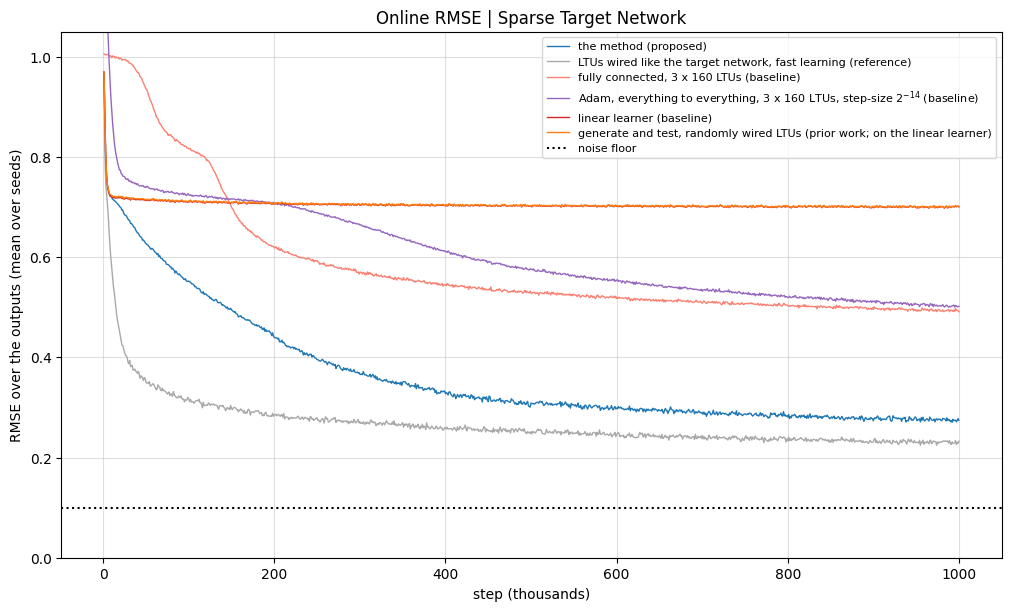

In [7]:
STEPS = (np.arange((LINEAR_STEPS + NUM_STEPS) // WINDOW) + 1) * WINDOW
METHODS = {'the method (proposed)': (SEARCH, 'tab:blue'),
           'LTUs wired like the target network, fast learning (reference)': (REFERENCE, 'darkgray'),
           f'fully connected, {N_DEPTHS} x {DENSE_WIDTH} LTUs (baseline)': ('dense', 'salmon'),
           f'Adam, everything to everything, {N_DEPTHS} x {DENSE_WIDTH} LTUs, '
           f'step-size $2^{{{ADAM_POWER}}}$ (baseline)': ('adam', 'tab:purple'),
           'linear learner (baseline)': (LINEAR, 'tab:red'),
           'generate and test, randomly wired LTUs (prior work; on the linear learner)': (PRIOR, 'tab:orange')}

fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
for label, (config, color) in METHODS.items():
    ax.plot(STEPS / 1000, rmse[config].mean(0), color=color, lw=1, label=label)
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands)', ylabel='RMSE over the outputs (mean over seeds)',
       ylim=(0, 1.05), title='Online RMSE | Sparse Target Network')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

## Results

The method finds much of the deep sparse target network, far more than fully connected networks, while generate and
test with randomly wired LTUs finds nothing. LTUs wired like the target network, which no longer wait for a linear
learner, end lower.

## Scaling

The method with 20, 40 (above) and 80 LTUs per depth. Search still runs every 10k steps and replaces 1 in 8 LTUs, so
it replaces more LTUs as there are more. 5 seeds each.

In [8]:
started = perf_counter()
scaled = {WIDTH: rmse[SEARCH]}
for width in (20, 80):
    set_width(width)
    config = (N_LTUS, *SEARCH[1:])
    scaled[width] = run([config])[config]
set_width(WIDTH)
print(f'{2 * N_SEEDS} runs in {perf_counter() - started:.0f}s')

10 runs in 324s


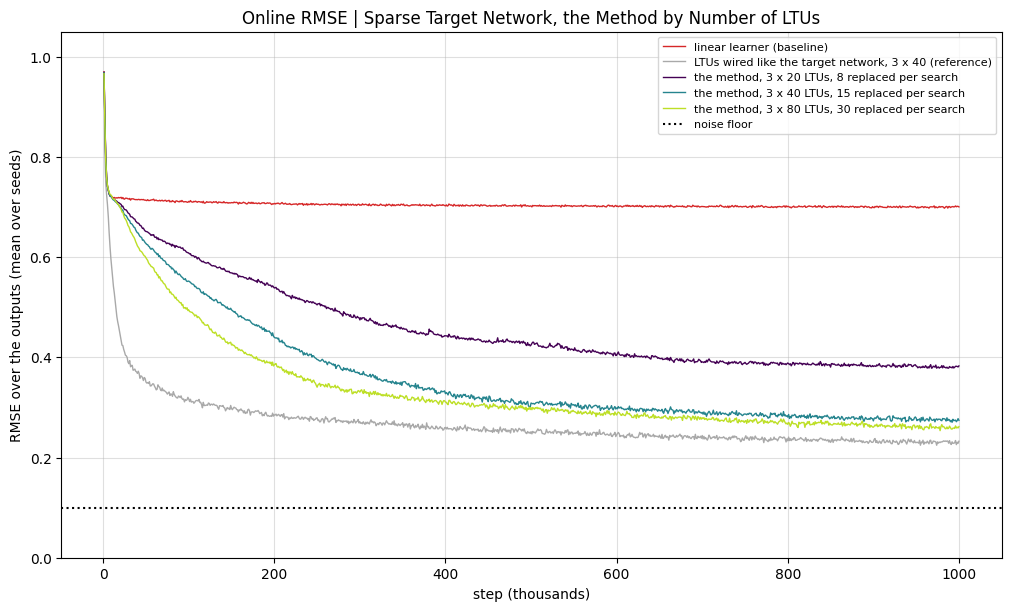

In [9]:
fig, ax = plt.subplots(figsize=(10, 6), layout='constrained')
ax.plot(STEPS / 1000, rmse[LINEAR].mean(0), color='tab:red', lw=1, label='linear learner (baseline)')
ax.plot(STEPS / 1000, rmse[REFERENCE].mean(0), color='darkgray', lw=1,
        label=f'LTUs wired like the target network, {N_DEPTHS} x {WIDTH} (reference)')
for i, width in enumerate(sorted(scaled)):
    ax.plot(STEPS / 1000, scaled[width].mean(0), color=plt.cm.viridis(0.9 * i / (len(scaled) - 1)), lw=1,
            label=f'the method, {N_DEPTHS} x {width} LTUs, '
                  f'{round(REPLACED_SHARE * N_DEPTHS * width)} replaced per search')
ax.axhline(NOISE_STD, color='black', ls=':', label='noise floor')
ax.set(xlabel='step (thousands)', ylabel='RMSE over the outputs (mean over seeds)', ylim=(0, 1.05),
       title='Online RMSE | Sparse Target Network, the Method by Number of LTUs')
ax.grid(alpha=0.4)
ax.legend(fontsize=8)
plt.show()

More LTUs make the method learn faster and end lower, with diminishing returns: 80 per depth (4 times the target
network's width) gains little over 40.

## Details

**Target.** The targets are the 100 outputs of a fixed target network plus $N(0, 0.1^2)$ noise (dotted line), on
standard normal inputs. Each target LTU reads 10 distinct units of lower depths (the inputs being depth 0), each picked
by choosing a lower depth uniformly, then a unit of that depth. Each output does the same over the hidden depths only.
Weights are $N(0, 1)$, each target LTU's threshold makes it fire 30% of the time, and each output has zero mean and unit
variance. A linear fit on the inputs explains about 62% of the targets' variance.

**Learner.** As in notebook 5, with 40 LTUs per depth (twice the target network's), and search replacing 15 LTUs every
10k steps. The swap runs from the top depth down.

**Prior work.** The same search and shadow weights, but a new LTU reads 20 sources drawn uniformly among those it may
read, with no fast learning, growth or swap.

**Fully connected network.** Network Autostep, 3 hidden layers of 160 LTUs, as in `../sparse_teacher.ipynb`.

**Adam.** 3 hidden layers of 160 LTUs (sigmoid derivative in the backward pass, not standardized). Each hidden layer
reads the inputs and every lower layer, and the outputs read the inputs and every hidden layer. LeCun uniform weights,
learning online from step 0. Step-size $2^{-14}$ was the best of $2^{-18}$ to $2^{-8}$ (by factors of 4, one seed
each); layer-to-layer networks and ReLUs did no better.

**The swap is needed here.** Without it (checked separately, 5 seeds), the method ends at RMSE 0.39 instead of 0.28.

**The reference is not the ceiling.** Network Autostep on the target network's wiring as set up in
`../sparse_teacher.ipynb`, without the linear learner or shadow weights, reaches 0.21 in 300k steps.